# Yale Urban Heat — Corrected Experiments

Dataset: `data/processed/heat/hyderabad_yale_heat.csv`

This notebook compares:
1. Data quality and exploratory analysis.
2. K-Means clustering using spatial + thermal features and thermal-only features.
3. Cluster profiles and pseudo-label classifier comparison (clearly treated as imitation of K-Means labels).
4. Spatially held-out regression for estimating measured daytime UHI from location and nighttime UHI.

**Important:** UHI is an urban-heat-island anomaly relative to a reference, not absolute air temperature. Cluster labels are not independently verified heat-risk categories. This dataset has no time-series target for forecasting.


## 1. Load the Yale dataset

In [12]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
PROJECT_ROOT = Path(r"C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics")
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "heat" / "hyderabad_yale_heat.csv"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "heat" / "yale_experiments"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

yale = pd.read_csv(DATA_PATH)
print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset shape:", yale.shape)
display(yale.head())


Project root: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics
Dataset path: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\heat\hyderabad_yale_heat.csv
Dataset shape: (5939, 5)


,pixel_id,latitude,longitude,daytime_uhi,nighttime_uhi
0,0,17.281340,78.472781,0.621574,-0.339550
1,1,17.281340,78.475476,0.621574,-0.339550
2,2,17.281340,78.634478,0.544587,-0.743359
3,3,17.281340,78.637172,0.544587,-0.743359
4,4,17.284035,78.472781,0.685822,-0.003218


## 2. Data quality audit

In [13]:
required_columns = [
    "pixel_id", "latitude", "longitude", "daytime_uhi", "nighttime_uhi"
]
missing_columns = [c for c in required_columns if c not in yale.columns]
if missing_columns:
    raise ValueError(f"Expected columns are missing: {missing_columns}")

print("Data types:")
display(yale.dtypes.to_frame("data_type"))
print("Missing values:")
display(yale.isna().sum().to_frame("missing_count"))
print("Duplicate rows:", yale.duplicated().sum())
print("Duplicate pixel IDs:", yale["pixel_id"].duplicated().sum())
print("Numeric summary:")
display(yale.describe().T)

numeric_columns = ["latitude", "longitude", "daytime_uhi", "nighttime_uhi"]
for col in numeric_columns:
    yale[col] = pd.to_numeric(yale[col], errors="coerce")

print("Missing values after numeric conversion:")
display(yale[numeric_columns].isna().sum().to_frame("missing_count"))


Data types:


,data_type
pixel_id,int64
latitude,float64
longitude,float64
daytime_uhi,float64
nighttime_uhi,float64


Missing values:


,missing_count
pixel_id,0
latitude,0
longitude,0
daytime_uhi,0
nighttime_uhi,0


Duplicate rows: 0
Duplicate pixel IDs: 0
Numeric summary:


,count,mean,std,min,25%,50%,75%,max
pixel_id,5939.0,2969.000000,1714.585956,0.000000,1484.500000,2969.000000,4453.500000,5938.000000
latitude,5939.0,17.428636,0.062812,17.281340,17.378358,17.432257,17.480766,17.548140
longitude,5939.0,78.474558,0.071493,78.300304,78.424272,78.478171,78.532070,78.637172
daytime_uhi,5939.0,-0.085957,0.789999,-5.896193,-0.418233,-0.067584,0.398328,1.554277
nighttime_uhi,5939.0,1.484519,0.881642,-1.308242,0.860078,1.503821,2.161631,3.185020


Missing values after numeric conversion:


,missing_count
latitude,0
longitude,0
daytime_uhi,0
nighttime_uhi,0


## 3. Prepare valid rows

In [14]:
# Keep rows with valid coordinates and both UHI measurements for the paired experiments.
analysis_data = yale.dropna(
    subset=["latitude", "longitude", "daytime_uhi", "nighttime_uhi"]
).copy()

if len(analysis_data) < 30:
    raise ValueError("Too few complete rows for the planned experiments.")

print("Rows available for experiments:", len(analysis_data))
print("Rows excluded due to missing required values:", len(yale) - len(analysis_data))


Rows available for experiments: 5939
Rows excluded due to missing required values: 0


## 4. Exploratory data analysis

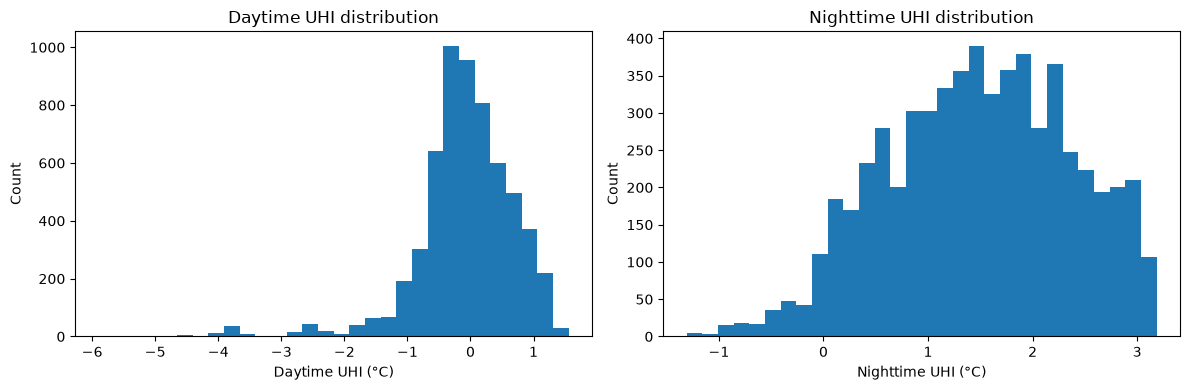

,count,mean,std,min,25%,50%,75%,max
daytime_uhi,5939.0,-0.085957,0.789999,-5.896193,-0.418233,-0.067584,0.398328,1.554277
nighttime_uhi,5939.0,1.484519,0.881642,-1.308242,0.860078,1.503821,2.161631,3.185020


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(analysis_data["daytime_uhi"], bins=30)
axes[0].set_title("Daytime UHI distribution")
axes[0].set_xlabel("Daytime UHI (°C)")
axes[0].set_ylabel("Count")

axes[1].hist(analysis_data["nighttime_uhi"], bins=30)
axes[1].set_title("Nighttime UHI distribution")
axes[1].set_xlabel("Nighttime UHI (°C)")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

display(analysis_data[["daytime_uhi", "nighttime_uhi"]].describe().T)


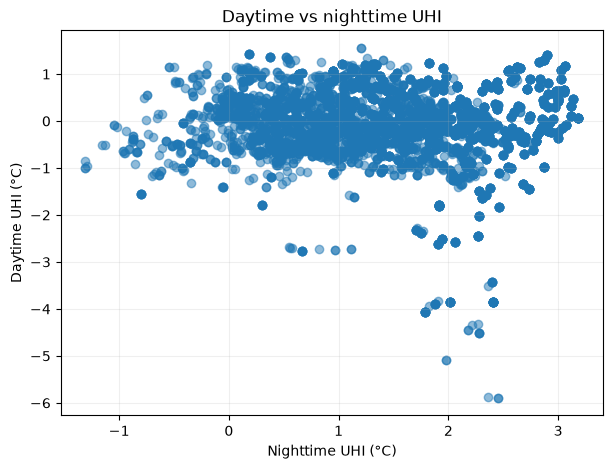

,latitude,longitude,daytime_uhi,nighttime_uhi
latitude,1.000000,-0.229425,-0.127933,-0.334409
longitude,-0.229425,1.000000,0.214553,0.069210
daytime_uhi,-0.127933,0.214553,1.000000,-0.049452
nighttime_uhi,-0.334409,0.069210,-0.049452,1.000000


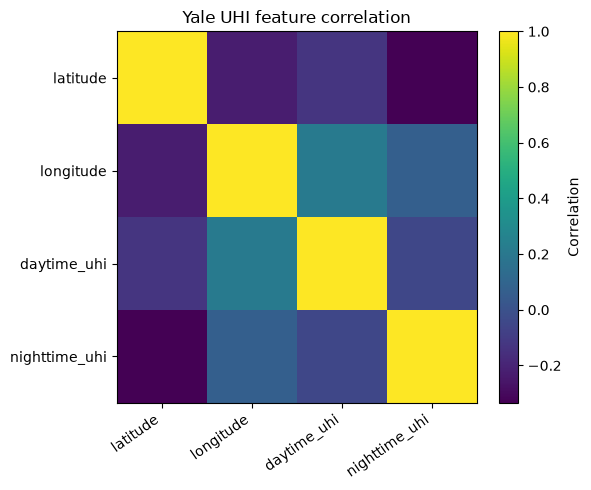

In [16]:
plt.figure(figsize=(7, 5))
plt.scatter(
    analysis_data["nighttime_uhi"],
    analysis_data["daytime_uhi"],
    alpha=0.5
)
plt.xlabel("Nighttime UHI (°C)")
plt.ylabel("Daytime UHI (°C)")
plt.title("Daytime vs nighttime UHI")
plt.grid(alpha=0.2)
plt.show()

corr = analysis_data[["latitude", "longitude", "daytime_uhi", "nighttime_uhi"]].corr()
display(corr)
plt.figure(figsize=(6, 5))
plt.imshow(corr, aspect="auto")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=35, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.colorbar(label="Correlation")
plt.title("Yale UHI feature correlation")
plt.tight_layout()
plt.show()


## 5. K-Means clustering comparison

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SPATIAL_THERMAL_FEATURES = [
    "latitude", "longitude", "daytime_uhi", "nighttime_uhi"
]
THERMAL_FEATURES = ["daytime_uhi", "nighttime_uhi"]

cluster_results = []
cluster_models = {}

for approach, features in [
    ("Spatial_Thermal", SPATIAL_THERMAL_FEATURES),
    ("Thermal_Only", THERMAL_FEATURES)
]:
    X = analysis_data[features].to_numpy()
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    for k in range(2, 11):
        model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
        labels = model.fit_predict(X_scaled)
        score = silhouette_score(X_scaled, labels)
        cluster_results.append({
            "approach": approach,
            "n_clusters": k,
            "inertia": float(model.inertia_),
            "silhouette_score": float(score)
        })
        cluster_models[(approach, k)] = (scaler, model)

cluster_comparison = pd.DataFrame(cluster_results)
display(cluster_comparison)
cluster_comparison.to_csv(
    OUTPUT_DIR / "yale_kmeans_approach_comparison.csv", index=False
)

best_rows = (
    cluster_comparison.sort_values("silhouette_score", ascending=False)
    .groupby("approach", as_index=False)
    .first()
)
print("Best K for each approach by silhouette score:")
display(best_rows)


,approach,n_clusters,inertia,silhouette_score
0,Spatial_Thermal,2,17488.450631,0.263210
1,Spatial_Thermal,3,13913.109245,0.270470
2,Spatial_Thermal,4,11387.791489,0.294926
3,Spatial_Thermal,5,9515.185988,0.303536
4,Spatial_Thermal,6,8369.143359,0.306292
5,Spatial_Thermal,7,7326.809420,0.306062
6,Spatial_Thermal,8,6490.712298,0.314358
7,Spatial_Thermal,9,6011.390075,0.312441
8,Spatial_Thermal,10,5601.391681,0.299191
9,Thermal_Only,2,7654.340549,0.356841


Best K for each approach by silhouette score:


,approach,n_clusters,inertia,silhouette_score
0,Spatial_Thermal,8,6490.712298,0.314358
1,Thermal_Only,3,5300.666900,0.380055


## 6. Cluster profiles

In [18]:
# Use the best silhouette-scoring K for each clustering approach.
cluster_profile_outputs = {}

for _, row in best_rows.iterrows():
    approach = row["approach"]
    k = int(row["n_clusters"])
    scaler, model = cluster_models[(approach, k)]
    features = SPATIAL_THERMAL_FEATURES if approach == "Spatial_Thermal" else THERMAL_FEATURES

    labels = model.predict(scaler.transform(analysis_data[features]))
    profile_data = analysis_data.copy()
    profile_data["cluster"] = labels

    profile = profile_data.groupby("cluster").agg(
        sample_count=("pixel_id", "size"),
        daytime_uhi_mean=("daytime_uhi", "mean"),
        daytime_uhi_median=("daytime_uhi", "median"),
        nighttime_uhi_mean=("nighttime_uhi", "mean"),
        nighttime_uhi_median=("nighttime_uhi", "median"),
        mean_latitude=("latitude", "mean"),
        mean_longitude=("longitude", "mean")
    ).reset_index()

    profile.to_csv(
        OUTPUT_DIR / f"yale_{approach.lower()}_cluster_profile.csv", index=False
    )
    cluster_profile_outputs[approach] = profile
    print(f"--- {approach}: K={k} ---")
    display(profile)


--- Spatial_Thermal: K=8 ---


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


,cluster,sample_count,daytime_uhi_mean,daytime_uhi_median,nighttime_uhi_mean,nighttime_uhi_median,mean_latitude,mean_longitude
0,0,781,-0.607570,-0.559976,2.051263,2.136869,17.414100,78.427505
1,1,1114,-0.036690,-0.067044,1.784744,1.757536,17.444317,78.534411
2,2,685,0.410589,0.407652,1.046050,1.101786,17.503054,78.442692
3,3,618,0.056876,0.126625,0.176227,0.175689,17.472965,78.565586
4,4,653,0.422323,0.501197,0.913690,0.978035,17.325631,78.499256
5,5,188,-2.887429,-2.569493,1.914312,1.943425,17.416647,78.468738
6,6,914,-0.426735,-0.421619,0.899919,0.897626,17.475258,78.364971
7,7,986,0.350488,0.327741,2.659034,2.744290,17.370232,78.495625


--- Thermal_Only: K=3 ---


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


,cluster,sample_count,daytime_uhi_mean,daytime_uhi_median,nighttime_uhi_mean,nighttime_uhi_median,mean_latitude,mean_longitude
0,0,555,-1.708720,-1.250995,2.013930,2.081995,17.420103,78.457942
1,1,2777,0.037967,-0.038298,0.716556,0.816746,17.447929,78.464472
2,2,2607,0.127506,0.049216,2.189855,2.121041,17.409901,78.488839


## 7. Pseudo-label classifier comparison (optional interpretation experiment)

The classifiers below learn to reproduce K-Means cluster assignments. Their scores are **not** independent heat-risk accuracy. To reduce leakage, K-Means is fitted only on the spatial training partition; its fitted centroids assign pseudo-labels to the held-out partition.

In [19]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Build geographic blocks for a spatially separated train/test split.
SPATIAL_BLOCK_DEGREES = 0.04
lat_block = np.floor(
    (analysis_data["latitude"] - analysis_data["latitude"].min()) / SPATIAL_BLOCK_DEGREES
).astype(int)
lon_block = np.floor(
    (analysis_data["longitude"] - analysis_data["longitude"].min()) / SPATIAL_BLOCK_DEGREES
).astype(int)
spatial_groups = (lat_block.astype(str) + "_" + lon_block.astype(str)).to_numpy()

if pd.Series(spatial_groups).nunique() < 4:
    raise ValueError("Too few geographic blocks for pseudo-label spatial split.")

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(
    splitter.split(analysis_data, groups=spatial_groups)
)

pseudo_features = THERMAL_FEATURES
X_pseudo = analysis_data[pseudo_features].to_numpy()
pseudo_scaler = StandardScaler()
X_train_scaled = pseudo_scaler.fit_transform(X_pseudo[train_idx])
X_test_scaled = pseudo_scaler.transform(X_pseudo[test_idx])

pseudo_kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=20)
y_train_cluster = pseudo_kmeans.fit_predict(X_train_scaled)
y_test_cluster = pseudo_kmeans.predict(X_test_scaled)

classifier_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(),
    "Gaussian Naive Bayes": GaussianNB()
}

classifier_results = []
for name, estimator in classifier_models.items():
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", estimator)
    ])
    pipeline.fit(X_pseudo[train_idx], y_train_cluster)
    predictions = pipeline.predict(X_pseudo[test_idx])
    classifier_results.append({
        "algorithm": name,
        "cluster_label_accuracy": accuracy_score(y_test_cluster, predictions),
        "cluster_label_balanced_accuracy": balanced_accuracy_score(y_test_cluster, predictions),
        "cluster_label_weighted_f1": f1_score(
            y_test_cluster, predictions, average="weighted", zero_division=0
        )
    })

classifier_comparison = pd.DataFrame(classifier_results).sort_values(
    "cluster_label_weighted_f1", ascending=False
)
display(classifier_comparison)
classifier_comparison.to_csv(
    OUTPUT_DIR / "yale_kmeans_pseudolabel_classifier_comparison.csv", index=False
)


,algorithm,cluster_label_accuracy,cluster_label_balanced_accuracy,cluster_label_weighted_f1
4,SVM,1.000000,1.000000,1.000000
2,Random Forest,1.000000,1.000000,1.000000
1,Decision Tree,0.998822,0.999022,0.998822
0,Logistic Regression,0.998822,0.999022,0.998822
3,KNN,0.989399,0.993408,0.989414
5,Gaussian Naive Bayes,0.989399,0.927338,0.988936


## 8. Spatially validated regression: estimate measured daytime UHI

Target: `daytime_uhi`  
Features: `latitude`, `longitude`, `nighttime_uhi`

This is cross-variable estimation of a measured UHI value. It is not a future forecast, and UHI is not absolute air temperature.

In [20]:
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

TARGET_COLUMN = "daytime_uhi"
REGRESSION_FEATURES = ["latitude", "longitude", "nighttime_uhi"]

X_reg = analysis_data[REGRESSION_FEATURES].copy()
y_reg = analysis_data[TARGET_COLUMN].copy()

# Reuse the spatial groups created above.
groups = pd.Series(spatial_groups, index=analysis_data.index)
group_splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(group_splitter.split(X_reg, y_reg, groups=groups))

X_train = X_reg.iloc[train_idx]
X_test = X_reg.iloc[test_idx]
y_train = y_reg.iloc[train_idx]
y_test = y_reg.iloc[test_idx]
groups_train = groups.iloc[train_idx]

n_splits = min(5, groups_train.nunique())
if n_splits < 2:
    raise ValueError("Not enough spatial training groups for GroupKFold.")
group_cv = GroupKFold(n_splits=n_splits)

regression_models = {
    "Linear Regression": (LinearRegression(), {}),
    "Ridge Regression": (Ridge(), {"model__alpha": [0.1, 1.0, 10.0, 100.0]}),
    "Lasso Regression": (
        Lasso(max_iter=20000),
        {"model__alpha": [0.001, 0.01, 0.1, 1.0]}
    ),
    "Decision Tree Regressor": (
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {
            "model__max_depth": [None, 4, 8, 12],
            "model__min_samples_leaf": [1, 3, 5]
        }
    ),
    "Random Forest Regressor": (
        RandomForestRegressor(
            n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
        ),
        {
            "model__max_depth": [None, 8, 15],
            "model__min_samples_leaf": [1, 3, 5],
            "model__max_features": [0.8, 1.0]
        }
    ),
    "Gradient Boosting Regressor": (
        GradientBoostingRegressor(random_state=RANDOM_STATE),
        {
            "model__n_estimators": [100, 200],
            "model__learning_rate": [0.03, 0.1],
            "model__max_depth": [2, 3]
        }
    ),
    "SVR": (
        SVR(),
        {
            "model__C": [1, 10, 100],
            "model__epsilon": [0.05, 0.1, 0.2],
            "model__kernel": ["rbf"]
        }
    )
}

search_results = []
best_estimators = {}

for model_name, (estimator, parameter_grid) in regression_models.items():
    print("Running spatial CV for:", model_name)
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grid,
        scoring="neg_mean_absolute_error",
        cv=group_cv,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )
    search.fit(X_train, y_train, groups=groups_train)
    best_estimators[model_name] = search.best_estimator_
    search_results.append({
        "algorithm": model_name,
        "spatial_cv_mae_c": -search.best_score_,
        "best_parameters": str(search.best_params_)
    })

cv_results = pd.DataFrame(search_results).sort_values("spatial_cv_mae_c")
display(cv_results)
cv_results.to_csv(
    OUTPUT_DIR / "yale_regression_spatial_cv_results.csv", index=False
)


Running spatial CV for: Linear Regression
Running spatial CV for: Ridge Regression
Running spatial CV for: Lasso Regression
Running spatial CV for: Decision Tree Regressor
Running spatial CV for: Random Forest Regressor
Running spatial CV for: Gradient Boosting Regressor
Running spatial CV for: SVR


,algorithm,spatial_cv_mae_c,best_parameters
4,Random Forest Regressor,0.392894,"{'model__max_depth': None, 'model__max_feature..."
3,Decision Tree Regressor,0.443223,"{'model__max_depth': 12, 'model__min_samples_l..."
6,SVR,0.500370,"{'model__C': 100, 'model__epsilon': 0.1, 'mode..."
5,Gradient Boosting Regressor,0.543104,"{'model__learning_rate': 0.03, 'model__max_dep..."
1,Ridge Regression,0.587621,{'model__alpha': 100.0}
0,Linear Regression,0.587785,{}
2,Lasso Regression,0.587796,{'model__alpha': 0.001}


## 9. Held-out spatial evaluation and baseline

In [21]:
best_algorithm_name = cv_results.iloc[0]["algorithm"]
best_regression_model = best_estimators[best_algorithm_name]

test_predictions = best_regression_model.predict(X_test)
selected_test_mae = mean_absolute_error(y_test, test_predictions)
selected_test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
selected_test_r2 = r2_score(y_test, test_predictions)

baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)
baseline_test_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_test_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_test_r2 = r2_score(y_test, baseline_predictions)

holdout_results = pd.DataFrame([
    {
        "model": best_algorithm_name,
        "test_MAE_C": selected_test_mae,
        "test_RMSE_C": selected_test_rmse,
        "test_R2": selected_test_r2
    },
    {
        "model": "Dummy mean baseline",
        "test_MAE_C": baseline_test_mae,
        "test_RMSE_C": baseline_test_rmse,
        "test_R2": baseline_test_r2
    }
])
display(holdout_results)
holdout_results.to_csv(
    OUTPUT_DIR / "yale_regression_holdout_evaluation.csv", index=False
)

print("Selected algorithm:", best_algorithm_name)
print("Spatial CV MAE:", cv_results.iloc[0]["spatial_cv_mae_c"])
print("Held-out MAE:", selected_test_mae)
print("Baseline MAE:", baseline_test_mae)


,model,test_MAE_C,test_RMSE_C,test_R2
0,Random Forest Regressor,0.240052,0.322938,0.508956
1,Dummy mean baseline,0.342554,0.461119,-0.001173


Selected algorithm: Random Forest Regressor
Spatial CV MAE: 0.3928935429038483
Held-out MAE: 0.24005195803547894
Baseline MAE: 0.34255364992842313


## 10. Save candidate model only if it beats the spatial holdout baseline

In [22]:
import joblib

candidate_is_better_than_baseline = selected_test_mae < baseline_test_mae

candidate_dir = PROJECT_ROOT / "models" / "heat" / "yale"
candidate_dir.mkdir(parents=True, exist_ok=True)

if candidate_is_better_than_baseline:
    model_path = candidate_dir / "yale_daytime_uhi_regression_candidate.joblib"
    metadata_path = candidate_dir / "yale_daytime_uhi_regression_metadata.json"

    joblib.dump(best_regression_model, model_path)

    metadata = {
        "dataset": "Hyderabad Yale Urban Heat",
        "dataset_file": "hyderabad_yale_heat.csv",
        "target": TARGET_COLUMN,
        "features": REGRESSION_FEATURES,
        "task": "cross-variable estimation of measured daytime UHI; not forecasting",
        "uhi_interpretation": "urban heat island anomaly; not absolute air temperature",
        "selected_algorithm": best_algorithm_name,
        "spatial_block_degrees": SPATIAL_BLOCK_DEGREES,
        "spatial_cv_mae_c": float(cv_results.iloc[0]["spatial_cv_mae_c"]),
        "heldout_spatial_test_mae_c": float(selected_test_mae),
        "heldout_spatial_test_rmse_c": float(selected_test_rmse),
        "heldout_spatial_test_r2": float(selected_test_r2),
        "baseline_heldout_test_mae_c": float(baseline_test_mae),
        "candidate_saved": True,
        "deployment_approval": "pending scientific and integration review"
    }
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    print("Candidate model saved:", model_path)
    print("Metadata saved:", metadata_path)
else:
    print(
        "No model saved: selected model did not beat the mean baseline "
        "on the held-out spatial test set."
    )


Candidate model saved: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\models\heat\yale\yale_daytime_uhi_regression_candidate.joblib
Metadata saved: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\models\heat\yale\yale_daytime_uhi_regression_metadata.json


## 11. Final interpretation

- K-Means groups Yale samples with similar UHI measurements; spatial + thermal clustering also considers geographic location.
- Silhouette score is an internal cluster-separation measure, not proof of real-world risk categories.
- Pseudo-label classifier scores measure how well classifiers reproduce K-Means assignments only.
- Regression estimates measured daytime UHI from coordinates and nighttime UHI. It is not a forecast.
- Yale UHI values are anomalies relative to a reference and must not be described as absolute temperature.
- A saved candidate remains pending scientific and integration review.